### Импорты и загрузка датасета

In [102]:
import pandas as pd
import kagglehub
from kagglehub import KaggleDatasetAdapter
from typing import List
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency
import numpy as np

In [2]:
import warnings
warnings.filterwarnings('ignore')

In [3]:
data_path = kagglehub.dataset_download(
    "jessemostipak/hotel-booking-demand",
    output_dir="data"
)

### Формулировка задачи и выбор метрик

**Выбранный датасет**: [Hotel Booking Demand](https://www.kaggle.com/datasets/jessemostipak/hotel-booking-demand)

Датасет содержит информацию о бронированиях городского и курортного отелей: когда была сделана бронь, на сколько ночей, кто является гостями, какой тип питания забронирован и другое.

**Бизнес-постановка задачи**

Реализовать модель-классификатор для определения, будет ли отменено бронирование. Это может позволить гостиницам заранее оценивать риск отмены, тем самым эффективнее планировать загрузку номеров и принимать решения по управлению бронированиями (например, если один человек делает бронирования и всегда отменяет их, стоит ли его занести в черный список).

**ML-задача**

Бинарная классификация. Для каждого бронирования необходимо предсказать, будет ли оно отменено (is_canceled = 1) или сохранится (is_canceled = 0).

**Выбор и обоснование метрик**

Основная метрика - **F1-score** для положительного класса (is_canceled = 1).
Эта метрика учитывает одновременно precision и recall: необходимо выявлять как можно больше бронирований, которые будут отменены, не создавая при этом слишком много ложных предупреждений.

Дополнительно:

- Precision - доля действительно отменённых бронирований среди всех бронирований, которые модель предсказала как отменённые. Высокий precision означает, что модель редко ошибочно помечает сохранённые бронирования как отменённые.

- Recall - доля найденных моделью отмен среди всех бронирований, которые действительно были отменены. Высокий recall означает, что модель пропускает мало реальных отмен.

- ROC-AUC - оценивает способность модели различать отменённые и сохранённые бронирования при различных порогах классификации.

**Описание столбцов датасета**

| Столбец | Перевод и краткое описание |
|---|---|
| `is_canceled` | Отмена бронирования: 1 - отменено, 0 - не отменено. |
| `lead_time` | Количество дней между оформлением бронирования и датой прибытия. |
| `arrival_date_year` | Год прибытия гостя. |
| `arrival_date_month` | Месяц прибытия гостя. |
| `arrival_date_week_number` | Номер недели года, на которую приходится прибытие. |
| `arrival_date_day_of_month` | День месяца, на который запланировано прибытие. |
| `stays_in_weekend_nights` | Количество ночей проживания в выходные (суббота и воскресенье). |
| `stays_in_week_nights` | Количество ночей проживания в будние дни (понедельник — пятница). |
| `adults` | Количество взрослых гостей. |
| `children` | Количество детей. |
| `babies` | Количество младенцев. |
| `meal` | Тип питания, включённого в бронирование. |
| `country` | Страна происхождения гостя (код страны ISO 3155–3:2013). |
| `market_segment` | Сегмент рынка, к которому относится бронирование (Например, “TA” - “Travel Agents”, “TO” - “Tour Operators”). |
| `distribution_channel` | Канал, через который оформлено бронирование. |
| `is_repeated_guest` | Был ли уже этот гость: 1 — да, 0 — нет. |
| `previous_cancellations` | Количество предыдущих бронирований, отменённых гостем. |
| `previous_bookings_not_canceled` | Количество предыдущих бронирований, которые не были отменены. |
| `reserved_room_type` | Код забронированного типа номера. |
| `assigned_room_type` | Код фактически назначенного типа номера. |
| `booking_changes` | Количество изменений бронирования после оформления. |
| `deposit_type` | Тип депозита или условия предоплаты. |
| `agent` | Идентификатор турагентства, оформившего бронирование. |
| `company` | Идентификатор компании, оформившей или оплачивающей бронирование. |
| `days_in_waiting_list` | Количество дней ожидания подтверждения бронирования. |
| `customer_type` | Тип бронирования: индивидуальное, групповое, контрактное или связанное с другими индивидуальными бронированиями. |
| `adr` | Средняя стоимость проживания за ночь. |
| `required_car_parking_spaces` | Количество необходимых парковочных мест. |
| `total_of_special_requests` | Количество особых пожеланий гостя. |
| `reservation_status` | Последний статус бронирования: отменено, выезд состоялся или гость не прибыл. |
| `reservation_status_date` | Дата последнего изменения статуса бронирования. |

### EDA

In [4]:
df = pd.read_csv(data_path + "/hotel_bookings.csv")

In [6]:
df.head()

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


#### Общий анализ

In [18]:
# Общая информация о датафрейме
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  str    
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  str    
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  meal                       

В целом типы данных соответствуют признакам, но некоторые столбцы требуют дополнительной проверки: например, `children`, `agent` и `company` имеют тип float64, хотя по сути должны представлять целочисленные значения (не может быть 2,5 гостя). Также `reservation_status_date` имеет строковый тип, хотя по сути это datetime, а месяц - строковый, хотя должен быть числом. Так как пока производится просто разведочный анализ данных, я не буду их приводить к нужному типу.



Также столбцы `reservation_status` и `reservation_status_date` в дальнейшем стоит исключить из тренировочного датасета, так как статус бронирования и дата его изменения могут содержать информацию, которая становится известна уже после наступления отмены, а также столбец `assigned_room_type` - номер обычно назначают при заезде (но это надо проверить), поэтому использование этих признаков может привести к неточной и, вероятно, завышенной оценке качества модели.

In [14]:
# Столбцы датафрейма
print(f"Количество столбцов: {len(df.columns)}")
print(f"Имена столбцов: {df.columns.tolist()}")

Количество столбцов: 32
Имена столбцов: ['hotel', 'is_canceled', 'lead_time', 'arrival_date_year', 'arrival_date_month', 'arrival_date_week_number', 'arrival_date_day_of_month', 'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'children', 'babies', 'meal', 'country', 'market_segment', 'distribution_channel', 'is_repeated_guest', 'previous_cancellations', 'previous_bookings_not_canceled', 'reserved_room_type', 'assigned_room_type', 'booking_changes', 'deposit_type', 'agent', 'company', 'days_in_waiting_list', 'customer_type', 'adr', 'required_car_parking_spaces', 'total_of_special_requests', 'reservation_status', 'reservation_status_date']


In [17]:
# Пропущенные значения в датафрейме
missing_values = df.isnull().sum()
print(f"Количество пропущенных значений в каждом столбце:\n{missing_values[missing_values > 0]}")

Количество пропущенных значений в каждом столбце:
children         4
country        488
agent        16340
company     112593
dtype: int64


В датафрейме 119 390 строк и 32 столбца. Пропущенные значения присутствуют в 4 столбцах, больше всего - в `agent` и `company`, поэтому им будет необходимо уделить особое внимание на этапе отбора признаков, поскольку значительная доля пропущенных значений может повлиять на информативность и целесообразность использования этих признаков в модели.

In [19]:
# Дубликаты в датафрейме
duplicate_rows = df.duplicated().sum()
print(f"Количество дубликатов в датафрейме: {duplicate_rows}")

Количество дубликатов в датафрейме: 31994


In [32]:
# Количество уникальных значений в столбцах
print(f"Количество уникальных значений в столбцах:\n{df.nunique().sort_values(ascending=True)}")

Количество уникальных значений в столбцах:
hotel                                2
is_canceled                          2
is_repeated_guest                    2
arrival_date_year                    3
deposit_type                         3
reservation_status                   3
customer_type                        4
required_car_parking_spaces          5
meal                                 5
babies                               5
distribution_channel                 5
children                             5
total_of_special_requests            6
market_segment                       8
reserved_room_type                  10
arrival_date_month                  12
assigned_room_type                  12
adults                              14
previous_cancellations              15
stays_in_weekend_nights             17
booking_changes                     21
arrival_date_day_of_month           31
stays_in_week_nights                35
arrival_date_week_number            53
previous_bookings_not

In [35]:
# Количество уникальных значений в категориальных столбцах
categorical_columns = df.select_dtypes(include=['object']).columns.tolist()
for col in categorical_columns:
    if col != 'reservation_status_date':  # Исключаем столбец с датой
        print(f"Столбец '{col}' имеет {df[col].nunique()} уникальных значений")
        print(f"Уникальные значения: {df[col].unique().tolist()}\n")

Столбец 'hotel' имеет 2 уникальных значений
Уникальные значения: ['Resort Hotel', 'City Hotel']

Столбец 'arrival_date_month' имеет 12 уникальных значений
Уникальные значения: ['July', 'August', 'September', 'October', 'November', 'December', 'January', 'February', 'March', 'April', 'May', 'June']

Столбец 'meal' имеет 5 уникальных значений
Уникальные значения: ['BB', 'FB', 'HB', 'SC', 'Undefined']

Столбец 'country' имеет 177 уникальных значений
Уникальные значения: ['PRT', 'GBR', 'USA', 'ESP', 'IRL', 'FRA', nan, 'ROU', 'NOR', 'OMN', 'ARG', 'POL', 'DEU', 'BEL', 'CHE', 'CN', 'GRC', 'ITA', 'NLD', 'DNK', 'RUS', 'SWE', 'AUS', 'EST', 'CZE', 'BRA', 'FIN', 'MOZ', 'BWA', 'LUX', 'SVN', 'ALB', 'IND', 'CHN', 'MEX', 'MAR', 'UKR', 'SMR', 'LVA', 'PRI', 'SRB', 'CHL', 'AUT', 'BLR', 'LTU', 'TUR', 'ZAF', 'AGO', 'ISR', 'CYM', 'ZMB', 'CPV', 'ZWE', 'DZA', 'KOR', 'CRI', 'HUN', 'ARE', 'TUN', 'JAM', 'HRV', 'HKG', 'IRN', 'GEO', 'AND', 'GIB', 'URY', 'JEY', 'CAF', 'CYP', 'COL', 'GGY', 'KWT', 'NGA', 'MDV', 'VEN'

`meal`, `market_segment` и `distribution_channel` содержат категорию Undefined. Надо подробнее рассмотреть её и как часто она встречается, а также проверить связь с целевой переменной `is_canceled`. Это позволит понять, что с ней лучше делать на этапе предобработки данных.

In [64]:
# Баланс классов в целевой переменной
target_column = 'is_canceled'
class_counts = df[target_column].value_counts().sort_index()
print(f"Баланс классов в целевой переменной '{target_column}':\n{class_counts}")

Баланс классов в целевой переменной 'is_canceled':
is_canceled
0    75166
1    44224
Name: count, dtype: int64


/var/folders/mj/2wfvq48n413ftp63mkhd64l40000gn/T/ipykernel_77696/3772506038.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(data=df, x="is_canceled", palette="crest")


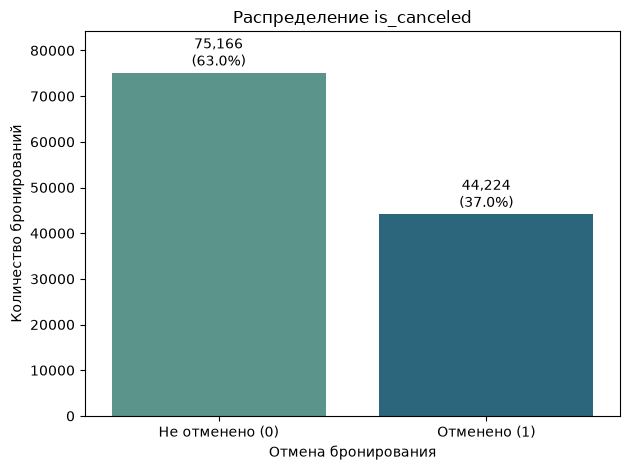

In [92]:
ax = sns.countplot(data=df, x="is_canceled", palette="crest")

for bar in ax.patches:
    count = int(bar.get_height())
    percent = count / len(df) * 100

    ax.text(
        bar.get_x() + bar.get_width() / 2,
        count + 500,
        f"{count:,}\n({percent:.1f}%)",
        ha="center",
        va="bottom"
    )

plt.title("Распределение is_canceled")
plt.xlabel("Отмена бронирования")
plt.ylabel("Количество бронирований")
plt.xticks([0, 1], ["Не отменено (0)", "Отменено (1)"])
plt.ylim(0, df["is_canceled"].value_counts().max() * 1.12)
plt.tight_layout()
plt.show()

Дисбаланс умеренный.

In [115]:
df.groupby(['deposit_type'])['is_canceled'].value_counts().reset_index()

,deposit_type,is_canceled,count
0,No Deposit,0,74947
1,No Deposit,1,29694
2,Non Refund,1,14494
3,Non Refund,0,93
4,Refundable,0,126
5,Refundable,1,36


Очень странно, что невозвратные брони в большинстве своем отменялись

In [129]:
df['is_canceled'].value_counts()

is_canceled
0    75166
1    44224
Name: count, dtype: int64

In [126]:
df.groupby(['required_car_parking_spaces'])['is_canceled'].value_counts().reset_index()

,required_car_parking_spaces,is_canceled,count
0,0,0,67750
1,0,1,44224
2,1,0,7383
3,2,0,28
4,3,0,3
5,8,0,2


Ни одна бронь с парковочным местом не отменена -> признак очень сильный, его можно превратить в бинарный, например, need_parking

#### Статистики

In [37]:
# Статистическая информация о числовых столбцах
df.describe().T

,count,mean,std,min,25%,50%,75%,max
is_canceled,119390.0,0.370416,0.482918,0.00,0.00,0.000,1.0,1.0
lead_time,119390.0,104.011416,106.863097,0.00,18.00,69.000,160.0,737.0
arrival_date_year,119390.0,2016.156554,0.707476,2015.00,2016.00,2016.000,2017.0,2017.0
arrival_date_week_number,119390.0,27.165173,13.605138,1.00,16.00,28.000,38.0,53.0
arrival_date_day_of_month,119390.0,15.798241,8.780829,1.00,8.00,16.000,23.0,31.0
stays_in_weekend_nights,119390.0,0.927599,0.998613,0.00,0.00,1.000,2.0,19.0
stays_in_week_nights,119390.0,2.500302,1.908286,0.00,1.00,2.000,3.0,50.0
adults,119390.0,1.856403,0.579261,0.00,2.00,2.000,2.0,55.0
children,119386.0,0.103890,0.398561,0.00,0.00,0.000,0.0,10.0
babies,119390.0,0.007949,0.097436,0.00,0.00,0.000,0.0,10.0


Числовые признаки `agent` и `company` на самом деле категориальные, их статистики бессмысленны.
Аномалии:
- минимальное значение в `adr` -6.38, хотя этот признак означает среднюю стоимость проживания за ночь и не может быть отрицательным
- количество взрослых в броне 55
- количество детей в броне 10

In [39]:
# Статистическая информация о категориальных столбцах
df.describe(include=["str", "object"]).T

,count,unique,top,freq
hotel,119390,2,City Hotel,79330
arrival_date_month,119390,12,August,13877
meal,119390,5,BB,92310
country,118902,177,PRT,48590
market_segment,119390,8,Online TA,56477
distribution_channel,119390,5,TA/TO,97870
reserved_room_type,119390,10,A,85994
assigned_room_type,119390,12,A,74053
deposit_type,119390,3,No Deposit,104641
customer_type,119390,4,Transient,89613


У `country` 177 значений, высокая кардинальность: нужны top-N + «Other» или target/frequency encoding

#### Распределения ключевых признаков, проверка аномалий и др.

##### Проверка зависимости целевой переменной от `reservation_status`, `reservation_status_date`, `assigned_room_type`

In [50]:
# Проверка зависимости целевой переменной от `reservation_status`, `assigned_room_type`
for col in ['reservation_status', 'assigned_room_type']:
    print(f"Зависимость целевой переменной от '{col}':")
    display(df.groupby([col])['is_canceled'].value_counts().unstack().fillna(0))


Зависимость целевой переменной от 'reservation_status':


is_canceled,0,1
reservation_status,,
Canceled,0.0,43017.0
Check-Out,75166.0,0.0
No-Show,0.0,1207.0


Зависимость целевой переменной от 'assigned_room_type':


is_canceled,0,1
assigned_room_type,,
A,41105.0,32948.0
B,1651.0,512.0
C,1929.0,446.0
D,18960.0,6362.0
E,5838.0,1968.0
F,2824.0,927.0
G,1773.0,780.0
H,461.0,251.0
I,358.0,5.0


Признак `reservation_status` (и `reservation_status_date` соответственно) раскрывает значение целевой переменной, поэтому его использование приведёт к утечке целевой переменной. При предобработке данных и обучении модели этот признак необходимо исключить.

Признак `assigned_room_type` не зависит напрямую от посещения или не посещения человеком отеля (я изначально предполагала, что тип номера  присваивается непосредственно при заселении) -> этот признак целесообразно сохранить при предобработке

##### Проверка дубликатов

In [51]:
df[df.duplicated(keep=False)]

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.00,0,1,Check-Out,2015-07-03
5,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.00,0,1,Check-Out,2015-07-03
21,Resort Hotel,0,72,2015,July,27,1,2,4,2,...,No Deposit,250.0,NaN,0,Transient,84.67,0,1,Check-Out,2015-07-07
22,Resort Hotel,0,72,2015,July,27,1,2,4,2,...,No Deposit,250.0,NaN,0,Transient,84.67,0,1,Check-Out,2015-07-07
39,Resort Hotel,0,70,2015,July,27,2,2,3,2,...,No Deposit,250.0,NaN,0,Transient,137.00,0,1,Check-Out,2015-07-07
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
119352,City Hotel,0,63,2017,August,35,31,0,3,3,...,No Deposit,9.0,NaN,0,Transient-Party,195.33,0,2,Check-Out,2017-09-03
119353,City Hotel,0,63,2017,August,35,31,0,3,3,...,No Deposit,9.0,NaN,0,Transient-Party,195.33,0,2,Check-Out,2017-09-03
119354,City Hotel,0,63,2017,August,35,31,0,3,3,...,No Deposit,9.0,NaN,0,Transient-Party,195.33,0,2,Check-Out,2017-09-03
119372,City Hotel,0,175,2017,August,35,31,1,3,1,...,No Deposit,42.0,NaN,0,Transient,82.35,0,1,Check-Out,2017-09-04


In [62]:
duplicate_counts = (
    df.value_counts()
    .rename("count")
    .reset_index()
    .query("count > 1")
    .sort_values("count", ascending=False)
)

display(duplicate_counts[['hotel', 'is_canceled', 'lead_time', 'arrival_date_year',
       'arrival_date_month', 'arrival_date_week_number',
       'arrival_date_day_of_month', 'adults', 'children', 'babies', 'market_segment', 'distribution_channel',
       'is_repeated_guest', 'previous_cancellations',
       'previous_bookings_not_canceled', 'booking_changes', 'count']].head(5))

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,adults,children,babies,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,booking_changes,count
0,City Hotel,0,256,2016,October,43,16,2,0.0,0,Online TA,TA/TO,0,0,0,0,7
1,Resort Hotel,0,24,2015,November,45,3,1,0.0,0,Corporate,Corporate,0,0,0,2,5
2,Resort Hotel,0,36,2015,November,45,7,1,0.0,0,Corporate,Corporate,0,0,0,1,4
3,Resort Hotel,0,36,2015,November,45,7,1,0.0,0,Corporate,Corporate,0,0,0,1,3
10,Resort Hotel,1,38,2015,November,46,9,1,0.0,0,Corporate,Corporate,0,0,0,3,2


In [43]:
# Распределение категорий среди дубликатов
duplicates = df[df.duplicated(keep=False)]
for col in ["market_segment", "customer_type", "hotel", "is_canceled"]:
    print(f"\n{col}:")
    display(
        duplicates[col]
        .value_counts(normalize=True)
        .round(2)
        .to_frame("proportion")
    )


market_segment:


,proportion
market_segment,
Groups,0.42
Offline TA/TO,0.30
Online TA,0.21
Corporate,0.04
Direct,0.03
Complementary,0.00
Aviation,0.00



customer_type:


,proportion
customer_type,
Transient,0.55
Transient-Party,0.42
Contract,0.03
Group,0.00



hotel:


,proportion
hotel,
City Hotel,0.79
Resort Hotel,0.21



is_canceled:


,proportion
is_canceled,
1,0.58
0,0.42


Можно заметить, что
- Дубли появляются не для каждого постояльца в номере (У бронирования в первой строке 7 дубликатов, а людей в броне 2)
- Число дублей не зависит от изменений брони

Также в датасете нет уникальных идентификаторов бронирования, поэтому не понять, реально ли бронирования уникальные или так удачно совпало

##### Проверка аномалий

In [181]:
# Бронирования с adr < 0
negative_adr_bookings = df[df['adr'] < 0]
print(f"Количество бронирований с adr < 0: {len(negative_adr_bookings)}")
display(negative_adr_bookings)

Количество бронирований с adr < 0: 1


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
14969,Resort Hotel,0,195,2017,March,10,5,4,6,2,...,No Deposit,273.0,NaN,0,Transient-Party,-6.38,0,0,Check-Out,2017-03-15


In [182]:
# Бронирования с adr = 0
zero_adr_bookings = df[df['adr'] == 0]
print(f"Количество бронирований с adr = 0: {len(zero_adr_bookings)}")
display(zero_adr_bookings)

Количество бронирований с adr = 0: 1959


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
125,Resort Hotel,0,32,2015,July,27,4,0,1,4,...,No Deposit,NaN,NaN,0,Transient,0.0,0,1,Check-Out,2015-07-05
167,Resort Hotel,0,111,2015,July,28,6,0,0,2,...,No Deposit,240.0,NaN,0,Transient,0.0,0,2,Check-Out,2015-07-06
168,Resort Hotel,0,0,2015,July,28,6,0,0,1,...,No Deposit,250.0,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-06
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
118631,City Hotel,0,78,2017,August,34,23,0,0,1,...,No Deposit,98.0,NaN,0,Transient-Party,0.0,0,0,Check-Out,2017-08-23
118762,City Hotel,0,1,2017,August,34,24,0,1,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,3,Check-Out,2017-08-25
118963,City Hotel,0,1,2017,August,35,27,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2017-08-27
119102,City Hotel,0,518,2017,August,34,26,2,1,1,...,No Deposit,229.0,NaN,0,Transient-Party,0.0,0,0,Check-Out,2017-08-29


In [183]:
zero_adr_bookings.groupby(['hotel', 'is_canceled'])['adr'].value_counts().reset_index()

,hotel,is_canceled,adr,count
0,City Hotel,0,0.0,1079
1,City Hotel,1,0.0,129
2,Resort Hotel,0,0.0,667
3,Resort Hotel,1,0.0,84


Возможно, что брони с adr = 0 - это брони за баллы отеля

In [21]:
# Бронирования с аномальным количеством взрослых

# Квантили количества взрослых
print(f"Квантили количества взрослых:\n{df['adults'].quantile([0.9, 0.95, 0.99])}")

# если смотреть брони где взрослых > 3 то 
# abnormal_adults_bookings['adults'].value_counts().sort_index() - adults 4     62 5      2, поэтому возьмем > 4

abnormal_adults_bookings = df[df['adults'] > 4].sort_values(by='adults', ascending=False)
print(f"Количество бронирований с аномальным количеством взрослых: {len(abnormal_adults_bookings)}")

abnormal_adults_bookings[['hotel', 'is_canceled', 'lead_time', 'arrival_date_year',
       'arrival_date_month', 'adults', 'children', 'babies', 'market_segment', 'is_repeated_guest', 'previous_cancellations', 'booking_changes', 'deposit_type', 'agent',
       'company']]

Квантили количества взрослых:
0.90    2.0
0.95    3.0
0.99    3.0
Name: adults, dtype: float64
Количество бронирований с аномальным количеством взрослых: 16


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,adults,children,babies,market_segment,is_repeated_guest,previous_cancellations,booking_changes,deposit_type,agent,company
2173,Resort Hotel,1,338,2015,October,55,0.0,0,Direct,0,0,0,No Deposit,NaN,NaN
1643,Resort Hotel,1,336,2015,September,50,0.0,0,Direct,0,0,0,No Deposit,NaN,NaN
1539,Resort Hotel,1,304,2015,September,40,0.0,0,Direct,0,0,0,No Deposit,NaN,NaN
1917,Resort Hotel,1,349,2015,September,27,0.0,0,Direct,0,0,0,No Deposit,NaN,NaN
1962,Resort Hotel,1,352,2015,September,27,0.0,0,Direct,0,0,0,No Deposit,NaN,NaN
1587,Resort Hotel,1,333,2015,September,26,0.0,0,Offline TA/TO,0,0,0,No Deposit,96.0,NaN
1752,Resort Hotel,1,340,2015,September,26,0.0,0,Offline TA/TO,0,0,0,No Deposit,96.0,NaN
1884,Resort Hotel,1,347,2015,September,26,0.0,0,Offline TA/TO,0,0,0,No Deposit,96.0,NaN
2003,Resort Hotel,1,354,2015,September,26,0.0,0,Offline TA/TO,0,0,0,No Deposit,96.0,NaN
2164,Resort Hotel,1,361,2015,October,26,0.0,0,Offline TA/TO,0,0,0,No Deposit,96.0,NaN


Все такие брони были отменены

+ у всех 16: Resort Hotel, 2015 год, lead_time > 300, No Deposit, все отменены - похоже на тестовые или ошибочные записи

In [25]:
# В таких бронях присутствует агент 96, посмотрим все ли его брони ошибочные
df.groupby('agent')['is_canceled'].value_counts().sort_index(ascending=False).loc[96]

is_canceled
1    244
0    293
Name: count, dtype: int64

In [67]:
columns = ['hotel', 'is_canceled', 'lead_time', 'arrival_date_year',
    'arrival_date_month', 'adults', 'children', 'babies', 
    'market_segment', 'is_repeated_guest', 'previous_cancellations', 
    'booking_changes', 'deposit_type', 'agent','company', 'reservation_status']
# Бронирования с нулевым количеством посетителей (adults + children + babies = 0) 
df[columns][
    (df['adults'] == 0) &
    (df['children'].apply(lambda x: int(x) if pd.notna(x) else 0) == 0) &
    (df['babies'] == 0)
]

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,adults,children,babies,market_segment,is_repeated_guest,previous_cancellations,booking_changes,deposit_type,agent,company,reservation_status
2224,Resort Hotel,0,1,2015,October,0,0.0,0,Corporate,0,0,1,No Deposit,NaN,174.0,Check-Out
2409,Resort Hotel,0,0,2015,October,0,0.0,0,Corporate,0,0,0,No Deposit,NaN,174.0,Check-Out
3181,Resort Hotel,0,36,2015,November,0,0.0,0,Groups,0,0,0,No Deposit,38.0,NaN,Check-Out
3684,Resort Hotel,0,165,2015,December,0,0.0,0,Groups,0,0,1,No Deposit,308.0,NaN,Check-Out
3708,Resort Hotel,0,165,2015,December,0,0.0,0,Groups,0,0,1,No Deposit,308.0,NaN,Check-Out
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
115029,City Hotel,0,107,2017,June,0,0.0,0,Online TA,0,0,1,No Deposit,7.0,NaN,Check-Out
115091,City Hotel,0,1,2017,June,0,0.0,0,Complementary,0,0,0,No Deposit,NaN,NaN,Check-Out
116251,City Hotel,0,44,2017,July,0,0.0,0,Online TA,0,0,2,No Deposit,425.0,NaN,Check-Out
116534,City Hotel,0,2,2017,July,0,0.0,0,Online TA,0,0,1,No Deposit,9.0,NaN,Check-Out


Очень странные брони без гостей, но которые были Check-Out

In [189]:
df[(df['stays_in_week_nights'] == 0) & (df['stays_in_weekend_nights'] == 0)][['is_canceled', 'stays_in_week_nights', 'stays_in_weekend_nights', 'reservation_status', 'reservation_status_date']]

,is_canceled,stays_in_week_nights,stays_in_weekend_nights,reservation_status,reservation_status_date
0,0,0,0,Check-Out,2015-07-01
1,0,0,0,Check-Out,2015-07-01
167,0,0,0,Check-Out,2015-07-06
168,0,0,0,Check-Out,2015-07-06
196,0,0,0,Check-Out,2015-07-07
...,...,...,...,...,...
115483,0,0,0,Check-Out,2017-07-06
117701,0,0,0,Check-Out,2017-08-08
118029,0,0,0,Check-Out,2017-08-14
118631,0,0,0,Check-Out,2017-08-23


Брони, где 0 ночей в общем, но при этом статус Check-Out, возможно это какая-то ошибка, и стоит удалить такие строки

##### Проверка агентов

In [47]:
df.groupby('agent').agg(
    cancellation_rate=('is_canceled', 'mean'),
    count=('is_canceled', 'count')
).reset_index().sort_values(by=['cancellation_rate', 'count'], ascending=False).head(20)


,agent,cancellation_rate,count
172,236.0,1.000000,247
135,170.0,1.000000,93
39,41.0,1.000000,75
205,286.0,1.000000,45
130,162.0,1.000000,37
171,235.0,1.000000,29
321,492.0,1.000000,28
230,323.0,1.000000,25
188,257.0,1.000000,24
53,60.0,1.000000,19


У некоторых агентов наблюдается очень высокая доля (даже 100%) отмен бронирований

##### Корреляция признаков

/var/folders/mj/2wfvq48n413ftp63mkhd64l40000gn/T/ipykernel_77696/1257107473.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=target_corr.values, y=target_corr.index, palette='coolwarm')


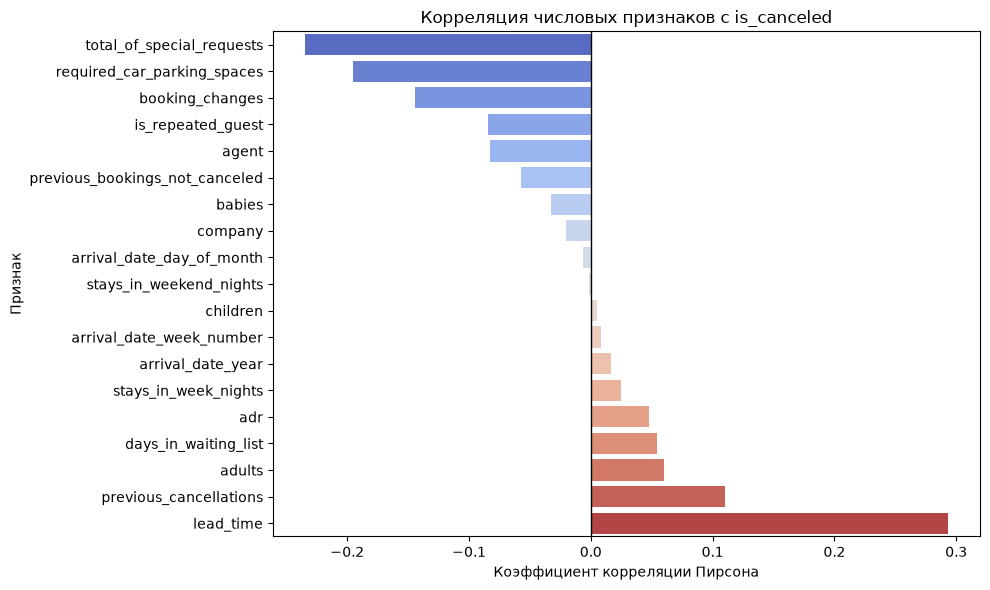

In [106]:
# Корреляция числовых признаков с целевой переменной
numeric_df = df.select_dtypes(include='number')

target_corr = (
    numeric_df.corr()['is_canceled']
    .drop('is_canceled')
    .sort_values()
)

plt.figure(figsize=(10, 6))
sns.barplot(x=target_corr.values, y=target_corr.index, palette='coolwarm')

plt.title('Корреляция числовых признаков с is_canceled')
plt.xlabel('Коэффициент корреляции Пирсона')
plt.ylabel('Признак')
plt.axvline(0, color='black', linewidth=1)
plt.tight_layout()
plt.show()

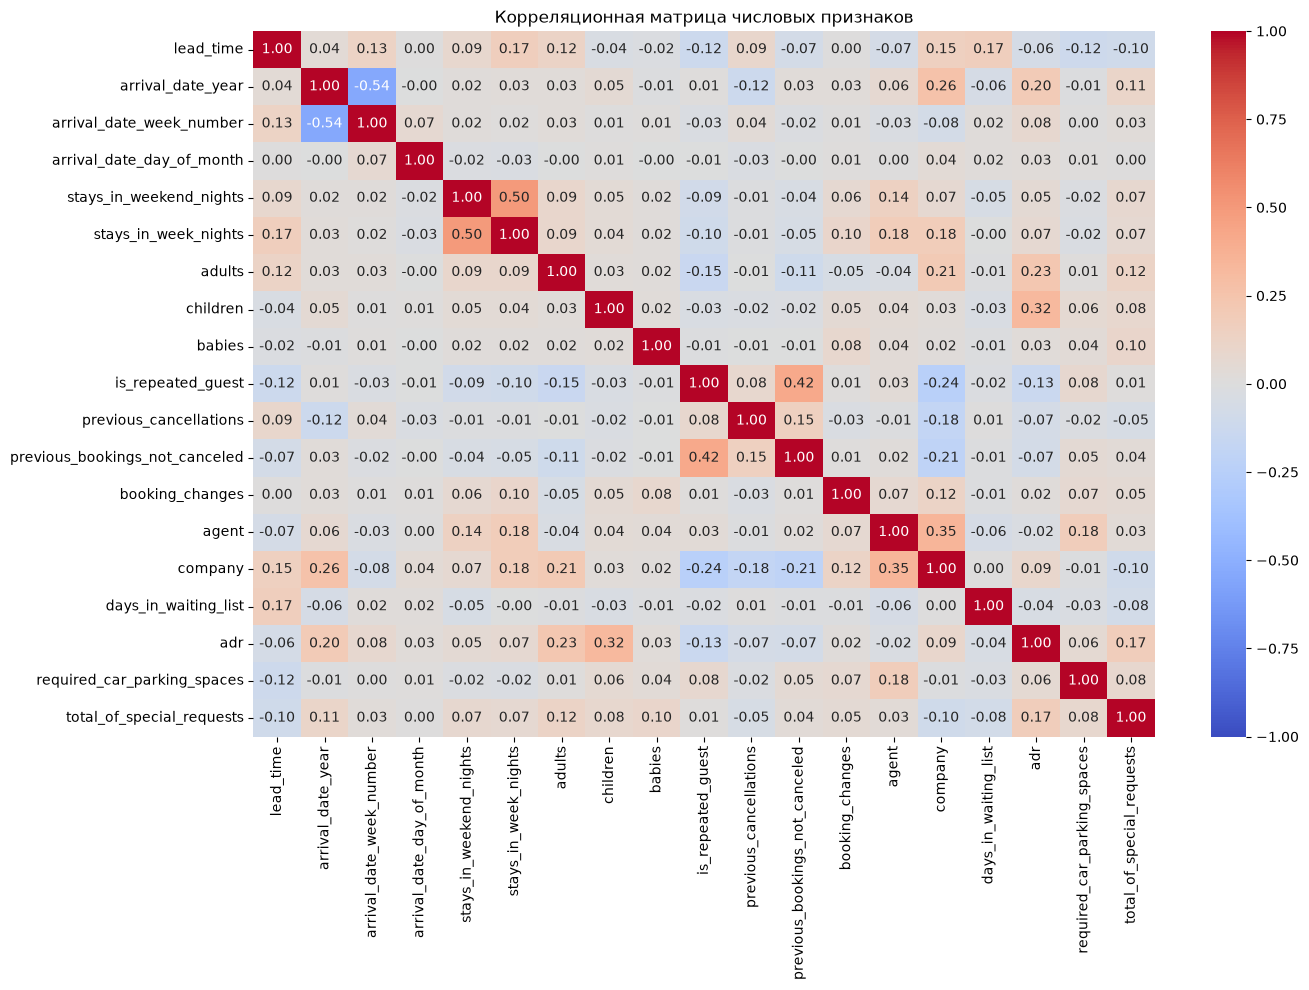

In [107]:
# Корреляционная матрица числовых признаков
corr_matrix = numeric_df.drop(columns='is_canceled').corr()

plt.figure(figsize=(14, 10))
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    center=0,
    vmin=-1,
    vmax=1
)

plt.title('Корреляционная матрица числовых признаков')
plt.tight_layout()
plt.show()

/var/folders/mj/2wfvq48n413ftp63mkhd64l40000gn/T/ipykernel_77696/4003437667.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = df.select_dtypes(include=['object', 'category']).columns.tolist()
/var/folders/mj/2wfvq48n413ftp63mkhd64l40000gn/T/ipykernel_77696/4003437667.py:22: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=cramers_corr.values, y=cramers_corr.index, palette='magma')


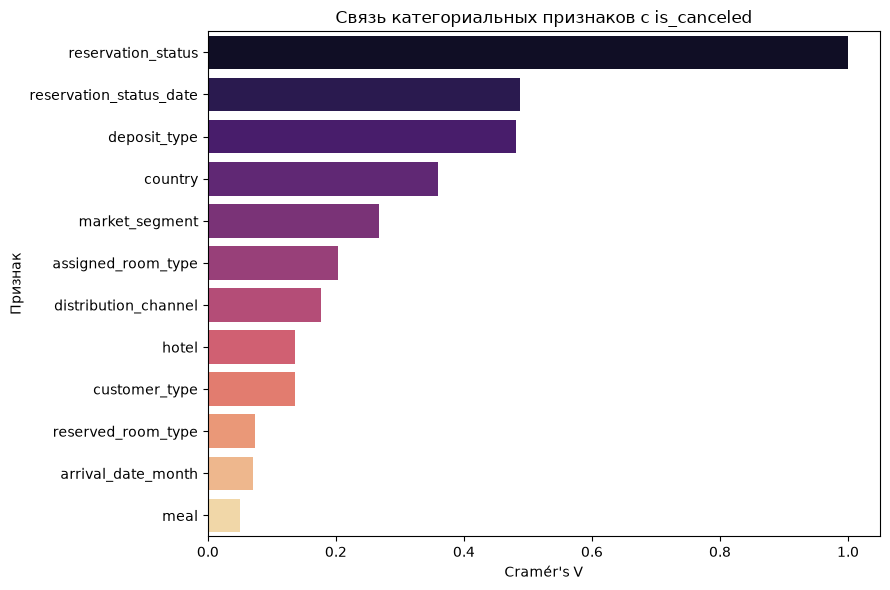

In [178]:
# Корреляция категориальных признаков с целевой переменной
# Для оценки силы связи между категориальными переменными можно использовать коэффициент Крамера
cat_cols = df.select_dtypes(include=['object', 'category']).columns.tolist()

def cramers_v(x, y):
    table = pd.crosstab(x, y)
    chi2 = chi2_contingency(table)[0]
    n = table.to_numpy().sum()
    r, k = table.shape

    if n == 0 or min(r, k) <= 1:
        return np.nan

    return np.sqrt(chi2 / (n * min(r - 1, k - 1)))

cramers_corr = pd.Series({
    col: cramers_v(df[col], df['is_canceled'])
    for col in cat_cols
}).sort_values(ascending=False)

plt.figure(figsize=(9, 6))
sns.barplot(x=cramers_corr.values, y=cramers_corr.index, palette='magma')

plt.title("Связь категориальных признаков с is_canceled")
plt.xlabel("Cramér's V")
plt.ylabel("Признак")
plt.tight_layout()
plt.show()

Как и ожидалось признак `reservation_status` и `reservation_status_date` очень коррелирует с целевой переменной, потому что он по сути содержит информацию о факте отмены.

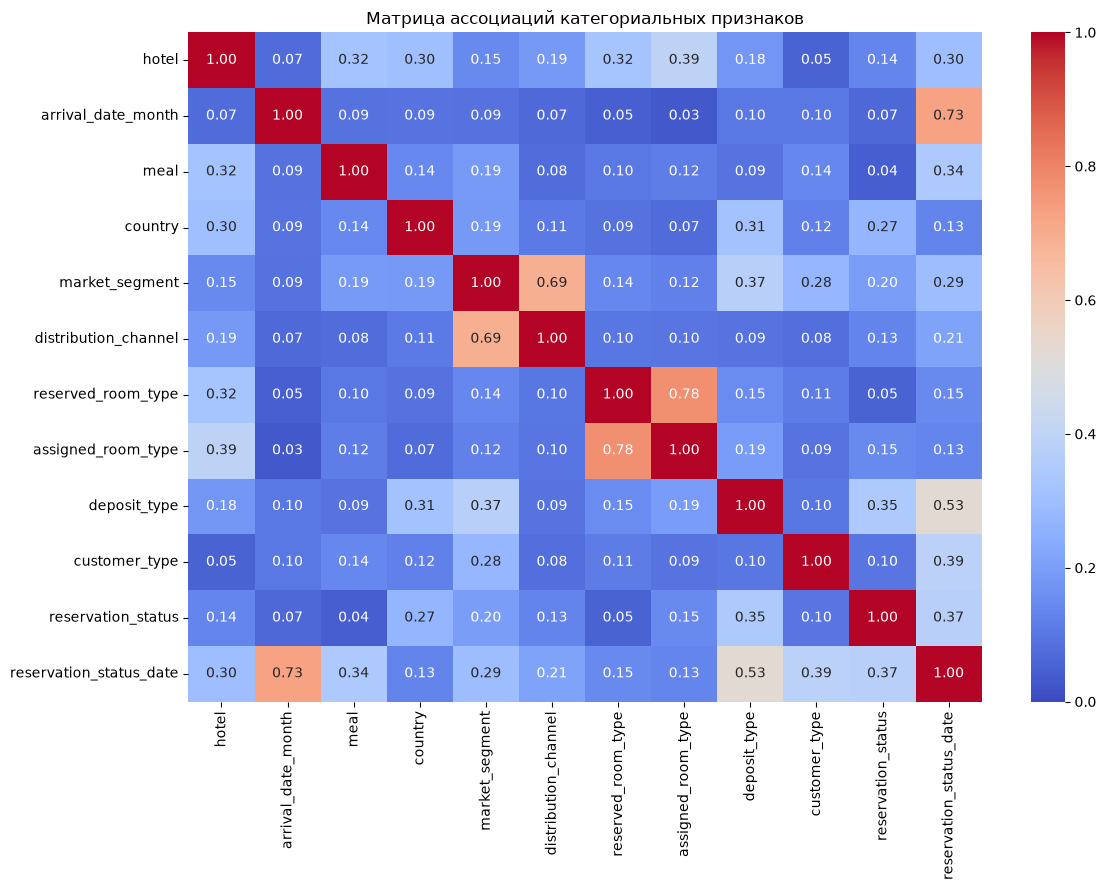

In [177]:
# Матрица ассоциаций категориальных признаков
cramers_matrix = pd.DataFrame(
    index=cat_cols,
    columns=cat_cols,
    dtype=float
)

for col1 in cat_cols:
    for col2 in cat_cols:
        cramers_matrix.loc[col1, col2] = cramers_v(
            df[col1], df[col2]
        )

plt.figure(figsize=(12, 9))
sns.heatmap(
    cramers_matrix,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    vmin=0,
    vmax=1
)

plt.title("Матрица ассоциаций категориальных признаков")
plt.tight_layout()
plt.show()

##### Сезонность

(0.0, 1.0)

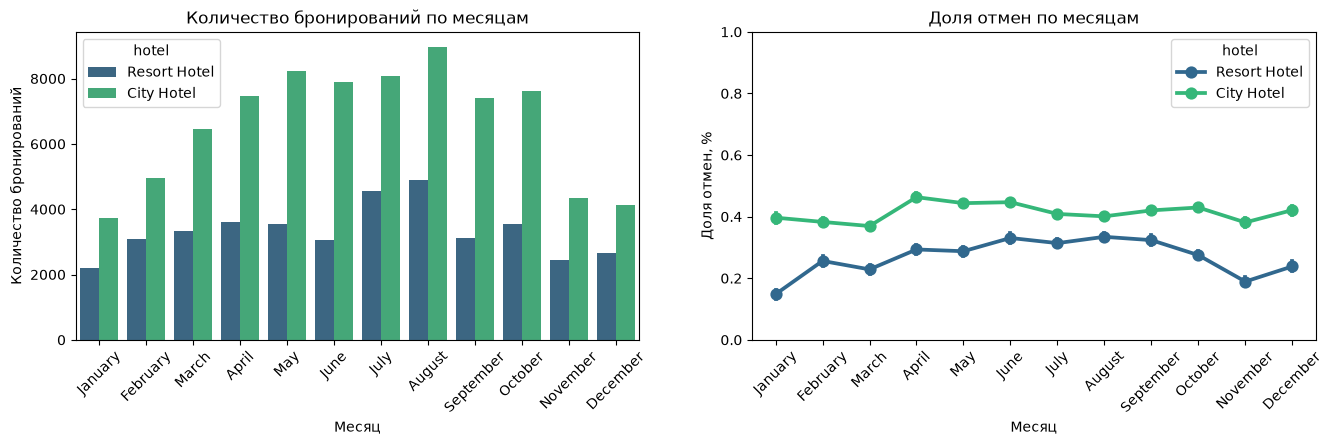

In [ ]:
months = ['January','February','March','April','May','June','July',
          'August','September','October','November','December']
fig, axes = plt.subplots(1, 2, figsize=(16, 4))
axes[0].set_title('Количество бронирований по месяцам')
axes[0].set_xlabel('Месяц')
axes[0].set_ylabel('Количество бронирований')
axes[0].tick_params(axis='x', rotation=45)
sns.countplot(data=df, x='arrival_date_month', hue='hotel', order=months, ax=axes[0], palette='viridis')

sns.pointplot(data=df, x='arrival_date_month', y='is_canceled', hue='hotel', order=months, ax=axes[1], palette='viridis')
axes[1].set_title('Доля отмен по месяцам')
axes[1].set_xlabel('Месяц')
axes[1].set_ylabel('Доля отмен, %')
axes[1].tick_params(axis='x', rotation=45)
plt.ylim(0, 1)

##### Выбросы

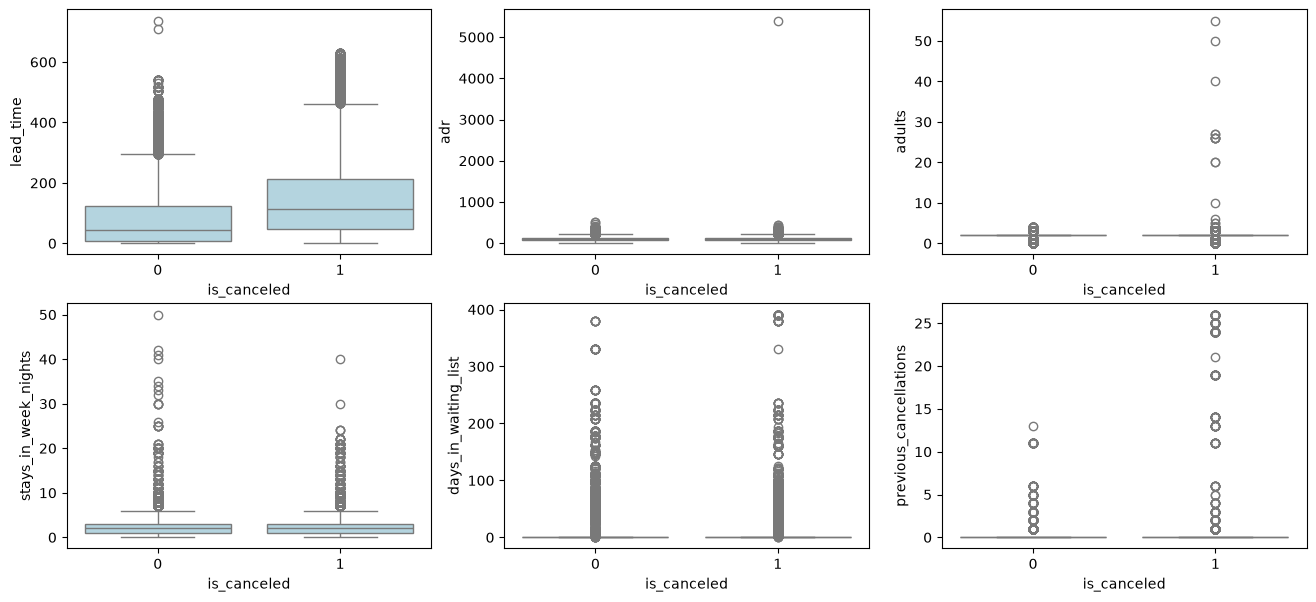

In [ ]:
# Выбросы
cols = ['lead_time', 'adr', 'adults', 'stays_in_week_nights', 'days_in_waiting_list', 'previous_cancellations']
fig, axes = plt.subplots(2, 3, figsize=(16, 7))
for ax, col in zip(axes.flat, cols):
    sns.boxplot(data=df, x='is_canceled', y=col, ax=ax, color='lightblue')


План предобработки:
- удалить утечки: `reservation_status`, `reservation_status_date`
- убрать аномалии: `adr` < 0 и `adr` = 5400, брони без гостей, `adults` > 4, брони без ночей
- решить, что делать с дубликатами, так как их очень много
- заполнить пропуски `children` -> 0, `country` -> Unknown, `agent` -> «нет агента»; `company` заменить флагом has_company
- заменить количество заказанных парковочных мест на признак need_parking
- для `country` нужны top-N + «Other» или target/frequency encoding
- месяц перевести в число
- добавить признаки `total_nights`, `total_guests`